# Una imagen como matriz y como vector

Utilizaremos inicialmente una imagen de $8 \times 8$ píxeles, representada mediante la matriz $X_{\text{fantoma}} \in \mathbb{R}^{8 \times 8}$. Esta clase de imagen de prueba suele denominarse **fantoma**: no corresponde a un escaneo real, sino que fue construida para estudiar el algoritmo de reconstrucción en condiciones controladas.

In [7]:
import numpy as np
import matplotlib.pyplot as plt


In [8]:
#Matriz de 8x8 que representa el fantoma
X_fantoma = np.array([
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
[0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
[0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)


#### a) Visualizar $X_{\text{fantoma}}$ mediante `plt.imshow`, utilizando una escala de grises con su referencia.

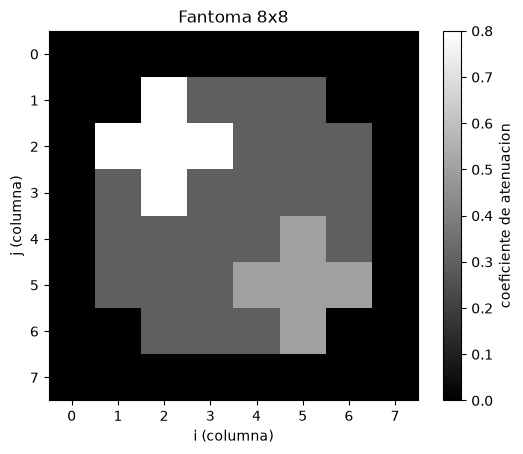

In [9]:
#Grafico del fantoma cada pixel se pinta segun su coeficiente de atenuacion
plt.imshow(X_fantoma, cmap="gray", vmin=0)
plt.colorbar(label="coeficiente de atenuacion")
plt.title("Fantoma 8x8")
plt.xlabel("i (columna)")
plt.ylabel("j (columna)")
plt.savefig('figuras/ejercicio_01a.png', dpi=150)
plt.show()

#### b) Convertir $X_{\text{fantoma}}$ en el vector $x_{\text{fantoma}} \in \mathbb{R}^{64}$ mediante `reshape(-1)`, que apila las filas de la matriz. Llamaremos $x_k$ al valor almacenado en la posición $k$, con $k = 0, \dots, 63$.

In [10]:
# Vector de 64 elementos que representa el fantoma
x_v_fantoma=X_fantoma.reshape(-1)
print("x_v_fantoma = ", x_v_fantoma)

x_v_fantoma =  [0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.8 0.3 0.3 0.3 0.  0.  0.  0.8
 0.8 0.8 0.3 0.3 0.3 0.  0.  0.3 0.8 0.3 0.3 0.3 0.3 0.  0.  0.3 0.3 0.3
 0.3 0.5 0.3 0.  0.  0.3 0.3 0.3 0.5 0.5 0.5 0.  0.  0.  0.3 0.3 0.3 0.5
 0.  0.  0.  0.  0.  0.  0.  0.  0.  0. ]


Al apilar las filas de la matriz con reshape(-1), las componentes 0 a 7 del vector se convierten en la fila 0 de la imagen, las 8 a 15 son la fila 1, y así sucesivamente

$$
X = \begin{pmatrix} X_{00} & \cdots & X_{07} \\ X_{10} & \cdots & X_{17} \\ \vdots & & \vdots \\ X_{70} & \cdots & X_{77} \end{pmatrix}
\;\longrightarrow\;
x = (X_{00}, \dots, X_{07},\ X_{10}, \dots, X_{17},\ \dots,\ X_{70}, \dots, X_{77})
$$

#### c) Recuperar la matriz original a partir de $X_{\text{fantoma}}$ y verificar numéricamente que ambas representaciones contienen la misma información.

In [11]:
#Matriz de 8x8 que representa el fantoma recuperada a partir del vector
X_fantoma_recuperada = x_v_fantoma.reshape(X_fantoma.shape)
print("X_fantoma_recuperada = ", X_fantoma_recuperada)

#Verificación numerica de que las matrices X_fantoma y X_fantoma_recuperada son iguales
#Son iguales si tienen la misma forma y mismos valores en las mismas posiciones
np.array_equal(X_fantoma, X_fantoma_recuperada)
print("")
print("¿Las matrices X_fantoma y X_fantoma_recuperada son iguales? ", np.array_equal(X_fantoma, X_fantoma_recuperada))



X_fantoma_recuperada =  [[0.  0.  0.  0.  0.  0.  0.  0. ]
 [0.  0.  0.8 0.3 0.3 0.3 0.  0. ]
 [0.  0.8 0.8 0.8 0.3 0.3 0.3 0. ]
 [0.  0.3 0.8 0.3 0.3 0.3 0.3 0. ]
 [0.  0.3 0.3 0.3 0.3 0.5 0.3 0. ]
 [0.  0.3 0.3 0.3 0.5 0.5 0.5 0. ]
 [0.  0.  0.3 0.3 0.3 0.5 0.  0. ]
 [0.  0.  0.  0.  0.  0.  0.  0. ]]

¿Las matrices X_fantoma y X_fantoma_recuperada son iguales?  True


`reshape` no modifica los datos, solo cambia cómo se leen. Por eso la matriz recuperada es idéntica a la original.

#### d) Explicar qué magnitud representa el valor de una componente $x_k$ en el modelo tomográfico. Interpretar qué significan valores altos, bajos y nulos de esa componente.

$x_k$ en el modelo tomográfico es el coeficiente de atenuación que hay en el pixel $k$. La atenuación es constante dentro de cada píxel. Es una propiedad del objeto, por lo que no depende del rayo ni del ángulo, lo que mide el escáner es la atenuación acumulada a lo largo de cada rayo, que es una suma de varios $x_k$

Según la formula $I = I_0\, e^{-\int \mu}$, cuanto mayor es la atenuación, menos intensidad llega al detector por lo que:
 
 - **$x_k$ alto**(Mucha atenuacion): El material dentro del tomografo frena los rayos X, por lo que llega poca intencidad al detector. Pero al contrario de lo que dice la intuición, en la imagen el píxel se ve claro. Esto ocurre porque se grafica la atenuación y no la intensidad detectada. (En la imagen del item a, son los píxeles en tonos blancos)

- **$x_k$ bajo**( poca atenuación): El rayo atraviesa ese píxel casi sin perder intensidad, y en la imagen se ve oscuro (en el ejemplo píxeles en tonos cercanos a negros). 
Para valores intermedios, los píxeles varían en tonos de gris.

 **$x_k$ nulo**(Sin atenuacion):En ese píxel no hay nada que atenúe, es decir el rayo no pierde intensidad al pasar por ahí. En la imagen se ve completamente negro 

#### e) Modificar un píxel de $X_{\text{fantoma}}$ y localizar qué componente $x_k$ cambia. Suponiendo que los índices comienzan en cero, expresar mediante una ecuación la relación entre los índices $(i, j)$ del píxel y su posición $k$ en el vector.

Componente que cambió: k = [21]
i*n + j = 21
(k // n, k % n) = (2, 5)


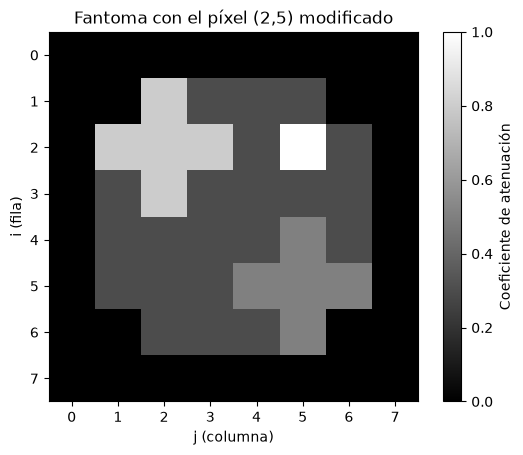

In [12]:
# Copia del fantoma, para no modificar el original
X_mod = X_fantoma.copy()

# Modificamos el píxel (i, j) = (2, 5)
i, j = 2, 5
X_mod[i, j] = 1.0

# Vectorizamos y buscamos qué componentes cambiaron
x_mod = X_mod.reshape(-1)
k = np.flatnonzero(x_mod != x_v_fantoma)
print("Componente que cambió: k =", k)

# Verificamos la fórmula k = i*n + j y su inversa
n = X_fantoma.shape[0]
print("i*n + j =", i * n + j)
print("(k // n, k % n) =", divmod(int(k[0]), n))

# Gráfico del fantoma modificado
plt.imshow(X_mod, cmap="gray", vmin=0)
plt.colorbar(label="Coeficiente de atenuación")
plt.title(f"Fantoma con el píxel ({i},{j}) modificado")
plt.xlabel("j (columna)")
plt.ylabel("i (fila)")
plt.savefig('figuras/ejercicio_01e.png', dpi=150)
plt.show()




Al modificar el píxel $(2, 5)$ cambió únicamente la componente $k = 21$ del vector. La relación entre los índices $(i, j)$ del píxel y su posición $k$ es

$$k = i\,n + j$$

ya que para llegar al comienzo de la fila $i$ hay que saltear $i$ filas completas de $n$ elementos cada una, y dentro de esa fila la columna $j$ está $j$ lugares más adelante. En el ejemplo $k = 2 \cdot 8 + 5 = 21$.

